In [20]:
import pandas as pd
from sklearn.model_selection import train_test_split

In [21]:
df = pd.read_csv(r"C:\Users\debas\OneDrive\Desktop\AIML\Datasets\plant_health_monitor_1.csv")
df.head()

,Plant_ID,Temperature_C,Humidity_%,Soil_Moisture_%,Soil_pH,Nutrient_Level,Light_Intensity_lux,Health_Status,VPD_kPa,Dew_Point_C,Stress_Factor_Count,Optimal_Growth_Flag,CO2_Level_ppm,Electrical_Conductivity_EC,Disease_Risk_Index
0,Plant_1,26.490142,73.993554,34.872326,5.546096,41.365064,18728.72095,0,0.900,21.47,2,No,445,1.96,41
1,Plant_2,24.585207,69.246337,42.832220,6.069807,49.687965,18639.75767,1,0.950,18.58,0,Yes,454,2.20,37
2,Plant_3,26.943066,60.596304,33.113701,6.293197,50.180169,14613.07048,1,1.400,18.68,1,No,434,1.30,30
3,Plant_4,29.569090,53.530632,40.380577,7.443844,54.726303,19009.72942,0,1.924,19.13,2,No,414,2.35,38
4,Plant_5,24.297540,66.982233,16.595780,6.778277,36.331416,22198.48725,0,1.003,17.77,1,No,464,2.19,29


In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Plant_ID                    1000 non-null   str    
 1   Temperature_C               1000 non-null   float64
 2   Humidity_%                  1000 non-null   float64
 3   Soil_Moisture_%             1000 non-null   float64
 4   Soil_pH                     1000 non-null   float64
 5   Nutrient_Level              1000 non-null   float64
 6   Light_Intensity_lux         1000 non-null   float64
 7   Health_Status               1000 non-null   int64  
 8   VPD_kPa                     1000 non-null   float64
 9   Dew_Point_C                 1000 non-null   float64
 10  Stress_Factor_Count         1000 non-null   int64  
 11  Optimal_Growth_Flag         1000 non-null   str    
 12  CO2_Level_ppm               1000 non-null   int64  
 13  Electrical_Conductivity_EC  1000 non-null   f

In [23]:
df = df.drop(columns=["Plant_ID"])
df = pd.get_dummies(
    df,
    columns=["Optimal_Growth_Flag"],
    drop_first=True,
    dtype=int
)

In [24]:
df.head()

,Temperature_C,Humidity_%,Soil_Moisture_%,Soil_pH,Nutrient_Level,Light_Intensity_lux,Health_Status,VPD_kPa,Dew_Point_C,Stress_Factor_Count,CO2_Level_ppm,Electrical_Conductivity_EC,Disease_Risk_Index,Optimal_Growth_Flag_Yes
0,26.490142,73.993554,34.872326,5.546096,41.365064,18728.72095,0,0.900,21.47,2,445,1.96,41,0
1,24.585207,69.246337,42.832220,6.069807,49.687965,18639.75767,1,0.950,18.58,0,454,2.20,37,1
2,26.943066,60.596304,33.113701,6.293197,50.180169,14613.07048,1,1.400,18.68,1,434,1.30,30,0
3,29.569090,53.530632,40.380577,7.443844,54.726303,19009.72942,0,1.924,19.13,2,414,2.35,38,0
4,24.297540,66.982233,16.595780,6.778277,36.331416,22198.48725,0,1.003,17.77,1,464,2.19,29,0


In [25]:
x = df.drop(columns=["Health_Status"])
y = df["Health_Status"]

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [27]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

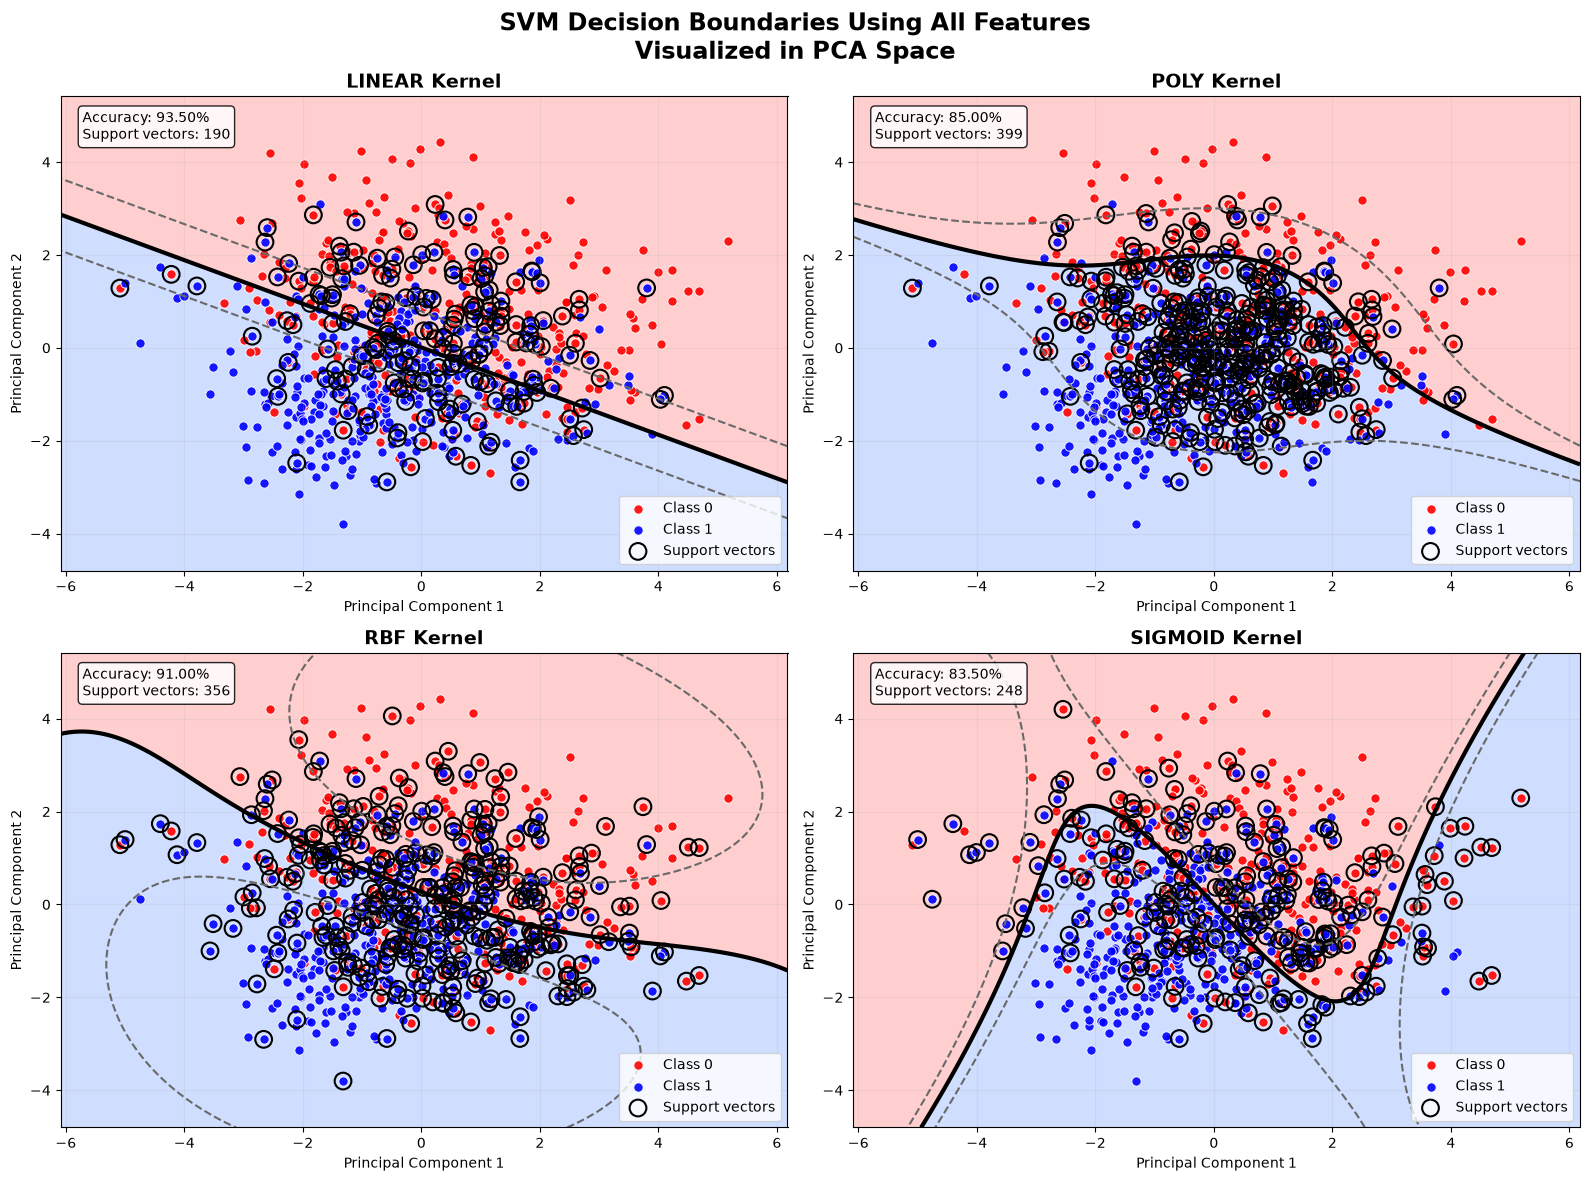

In [28]:
# Improved PCA visualization using the full-feature SVM models
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

pca_plot = PCA(n_components=2)
X_train_pca_plot = pca_plot.fit_transform(x_train_scaled)

kernels = ["linear", "poly", "rbf", "sigmoid"]
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Clear red and blue colours for the two decision regions
region_colors = ["#ffc7c7", "#c7d9ff"]
point_colors = ["red", "blue"]

for ax, kernel in zip(axes.ravel(), kernels):
    # Train using every input feature
    model = SVC(kernel=kernel)
    model.fit(x_train_scaled, y_train)

    # Full-feature accuracy
    y_pred = model.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, y_pred)

    x_min, x_max = X_train_pca_plot[:, 0].min() - 1, X_train_pca_plot[:, 0].max() + 1
    y_min, y_max = X_train_pca_plot[:, 1].min() - 1, X_train_pca_plot[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 400),
        np.linspace(y_min, y_max, 400)
    )

    # Convert PCA points back to all original scaled features
    grid_pca = np.c_[xx.ravel(), yy.ravel()]
    grid_full = pca_plot.inverse_transform(grid_pca)
    decision_values = model.decision_function(grid_full).reshape(xx.shape)

    # Discrete decision regions: red and blue
    regions = (decision_values >= 0).astype(int)
    ax.contourf(
        xx,
        yy,
        regions,
        levels=[-0.5, 0.5, 1.5],
        colors=region_colors,
        alpha=0.85
    )

    # Optimal hyperplane and margins
    ax.contour(
        xx, yy, decision_values,
        levels=[0],
        colors="black",
        linewidths=3,
        linestyles="-"
    )
    ax.contour(
        xx, yy, decision_values,
        levels=[-1, 1],
        colors="dimgray",
        linewidths=1.5,
        linestyles="--"
    )

    y_train_array = np.asarray(y_train)

    # Training points
    for class_value, color, label in zip([0, 1], point_colors, ["Class 0", "Class 1"]):
        mask = y_train_array == class_value
        ax.scatter(
            X_train_pca_plot[mask, 0],
            X_train_pca_plot[mask, 1],
            color=color,
            edgecolors="white",
            linewidths=0.7,
            s=45,
            alpha=0.9,
            label=label
        )

    # Support vectors shown with a black ring only
    support_vectors_pca = pca_plot.transform(model.support_vectors_)
    ax.scatter(
        support_vectors_pca[:, 0],
        support_vectors_pca[:, 1],
        facecolors="none",
        edgecolors="black",
        linewidths=1.5,
        s=145,
        label="Support vectors"
    )

    ax.set_title(f"{kernel.upper()} Kernel", fontsize=14, fontweight="bold")
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
    ax.text(
        0.03,
        0.97,
        f"Accuracy: {accuracy:.2%}\nSupport vectors: {len(model.support_)}",
        transform=ax.transAxes,
        verticalalignment="top",
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.85)
    )
    ax.legend(loc="lower right")
    ax.grid(alpha=0.2)

plt.suptitle(
    "SVM Decision Boundaries Using All Features\nVisualized in PCA Space",
    fontsize=17,
    fontweight="bold"
)
plt.tight_layout()
plt.show()
